# Python

In [1]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

## Visualizing polymers in a 3D lattice

#### Importing full lattice state

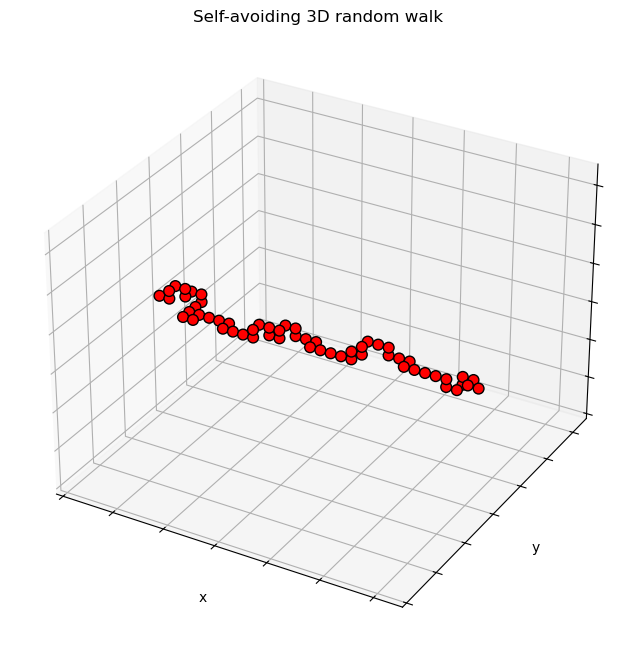

In [20]:
# import json data
dirname = "20251024/testpoly_frame10" 
# dirname = "20250924/testpoly" 
lattice = json.load(open("data/"+dirname+".json"))
lattice = np.array(lattice)

# Get coordinates where array == 1
coords1 = np.argwhere(lattice[..., -1] == 1)
coords2 = np.argwhere(lattice[..., -2] == 1)
x1, y1, z1 = coords1[:, 2], coords1[:, 1], coords1[:, 0]
x2, y2, z2 = coords2[:, 2], coords2[:, 1], coords2[:, 0]

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(x1, y1, z1, s=40, c='blue', marker='o', alpha=0.5)
ax.scatter(x2, y2, z2, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

#### Importing species coordinates

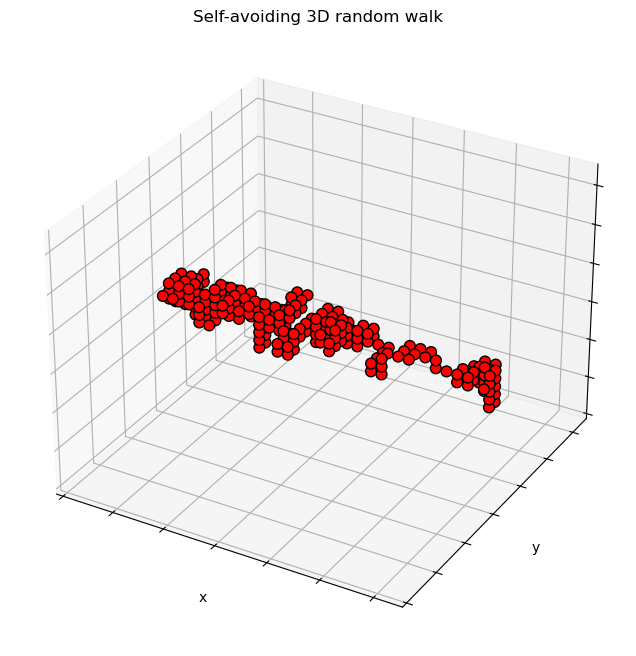

In [71]:
# import json data
dirname = "20251028/testpoly_frame2000" 
# dirname = "20250924/testpoly" 
slist = json.load(open("data/"+dirname+".json"))

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for key, val in slist.items():
    x, y, z = val["coords"] 
    
    if val["name"][:4] == "poly":
        ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

## Animations

#### Example

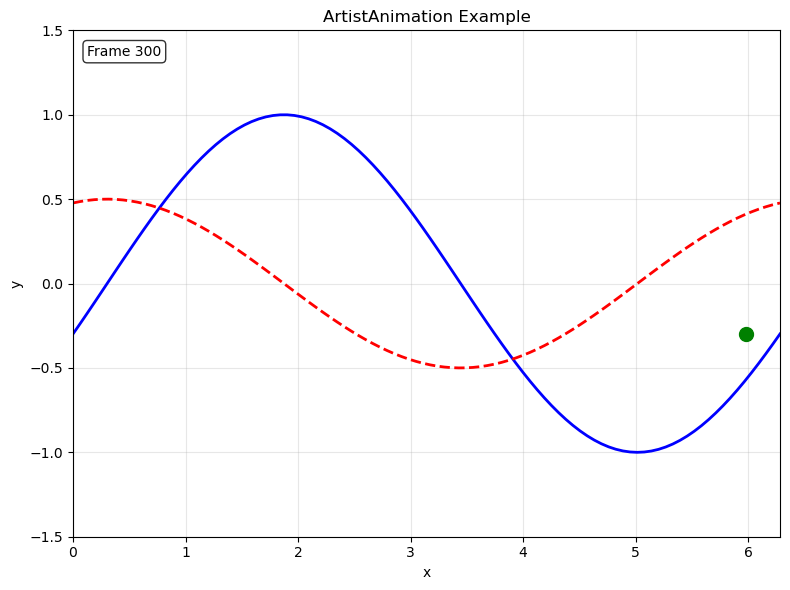

In [ ]:
# Basic example of ArtistAnimation in matplotlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Create figure and axis
fig, ax = plt.subplots(figsize=(8, 6))

# Generate data for animation
x = np.linspace(0, 2*np.pi, 100)
frames = []

# Create a series of artists for each frame
for i in range(300):
    # Create different artists for this frame
    phase = i * 0.02
    y1 = np.sin(x + phase)
    y2 = np.cos(x + phase) * 0.5
    
    # Plot multiple elements as artists
    line1, = ax.plot(x, y1, 'b-', linewidth=2, label='sin wave')
    line2, = ax.plot(x, y2, 'r--', linewidth=2, label='cos wave')
    scatter = ax.scatter([phase], [np.sin(phase)], c='green', s=100, zorder=5)
    text = ax.text(0.02, 0.95, f'Frame {i+1}', transform=ax.transAxes, 
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Group all artists for this frame
    frame_artists = [line1, line2, scatter, text]
    frames.append(frame_artists)

# Set up the plot
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('ArtistAnimation Example')
ax.grid(True, alpha=0.3)

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=100, blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

# Optional: Save as GIF (uncomment if needed)
anim.save('media/sinewaves.gif', writer='pillow', fps=25)

#### Polymer

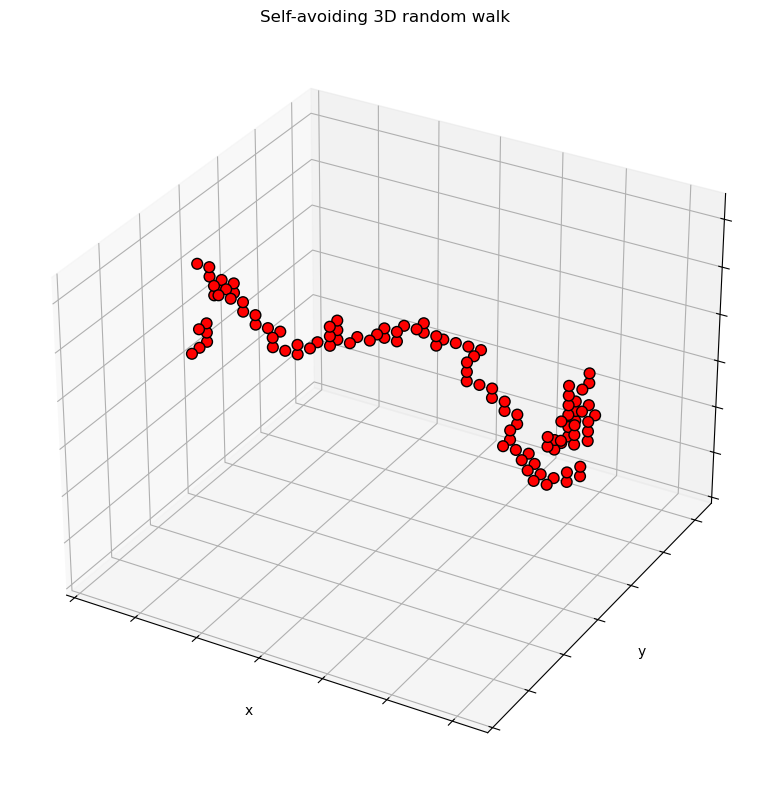

In [42]:
# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
dirname = "20251024/testpoly" 

frames = []

for i in range(2000):
    lattice = json.load(open("data/"+dirname+"_frame"+str(i+1)+".json"))
    lattice = np.array(lattice)

    # Get coordinates where array == 1
    coords = np.argwhere(lattice[..., -2] == 1)
    x, y, z = coords[:, 2], coords[:, 1], coords[:, 0]

    scatter = ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

    frame_artists = [scatter]
    frames.append(frame_artists)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=10, 
                                 blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

anim.save('media/polymer_repulsive.mp4', writer="ffmpeg", fps=25)